# 01 — Exploratory Data Analysis & Preprocessing

**Project:** Credit Card Fraud Detection  
**Dataset:** Classic ULB Credit Card Fraud Dataset (PCA-transformed features)

**Goals of this notebook:**
- Load and understand the dataset
- Perform thorough Exploratory Data Analysis (EDA)
- Analyze class imbalance
- Explore feature distributions (especially Amount & Time)
- Apply basic preprocessing (scaling)
- Create a clean train-test split
- Save processed data for the next notebooks

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import classification_report

# Settings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# !pip install datasets   # run this once if needed

from datasets import load_dataset

dataset = load_dataset("Barvero/Credit_Card_Fraud_Analysis_Project")
df = dataset["train"].to_pandas()

# Option 2: If you prefer downloading the classic Kaggle version manually
# df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")
df.head()

Repo card metadata block was not found. Setting CardData to empty.


Dataset loaded successfully!
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [6]:
print("DATASET OVERVIEW")

print(f"\nShape of the dataset: {df.shape}")
print(f"Number of rows   : {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

DATASET OVERVIEW

Shape of the dataset: (284807, 31)
Number of rows   : 284,807
Number of columns: 31

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time        int64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values:
0

Duplicate rows: 1081


In [7]:
print("Statistical Summary of Numerical Features:")
display(df.describe().T)

Statistical Summary of Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0000,94813.8596,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
V1,284807.0000,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,284807.0000,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577
V3,284807.0000,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826
V4,284807.0000,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753
V5,284807.0000,0.0000,1.3802,-113.7433,-0.6916,-0.0543,0.6119,34.8017
V6,284807.0000,0.0000,1.3323,-26.1605,-0.7683,-0.2742,0.3986,73.3016
V7,284807.0000,-0.0000,1.2371,-43.5572,-0.5541,0.0401,0.5704,120.5895
V8,284807.0000,0.0000,1.1944,-73.2167,-0.2086,0.0224,0.3273,20.0072
V9,284807.0000,-0.0000,1.0986,-13.4341,-0.6431,-0.0514,0.5971,15.5950


Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Percentage:
Class
0   99.8273
1    0.1727
Name: proportion, dtype: float64


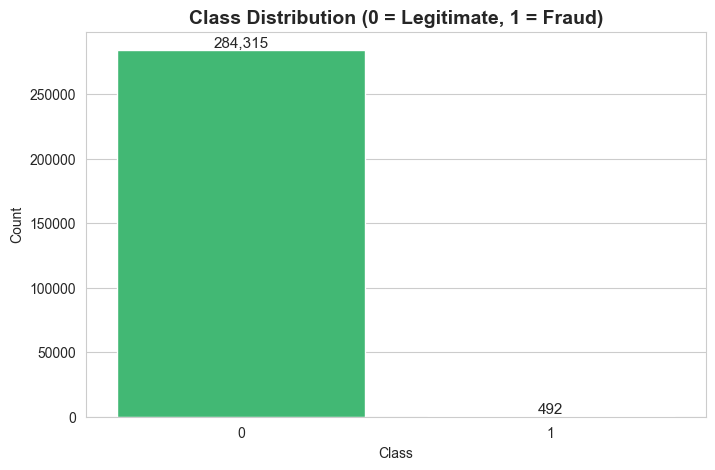


 Fraud rate: 0.1727%
 Imbalance ratio (Legitimate : Fraud) ≈ 578 : 1


In [8]:
print("Class Distribution:")
print(df['Class'].value_counts())
print("\nClass Percentage:")
print(df['Class'].value_counts(normalize=True) * 100)

# Visualization
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='Class', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Class Distribution (0 = Legitimate, 1 = Fraud)', fontsize=14, fontweight='bold')
plt.xlabel('Class')
plt.ylabel('Count')

# Add count labels
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11)

plt.show()

fraud_percentage = df['Class'].mean() * 100
print(f"\n Fraud rate: {fraud_percentage:.4f}%")
print(f" Imbalance ratio (Legitimate : Fraud) ≈ { (df['Class']==0).sum() / (df['Class']==1).sum() :.0f} : 1")

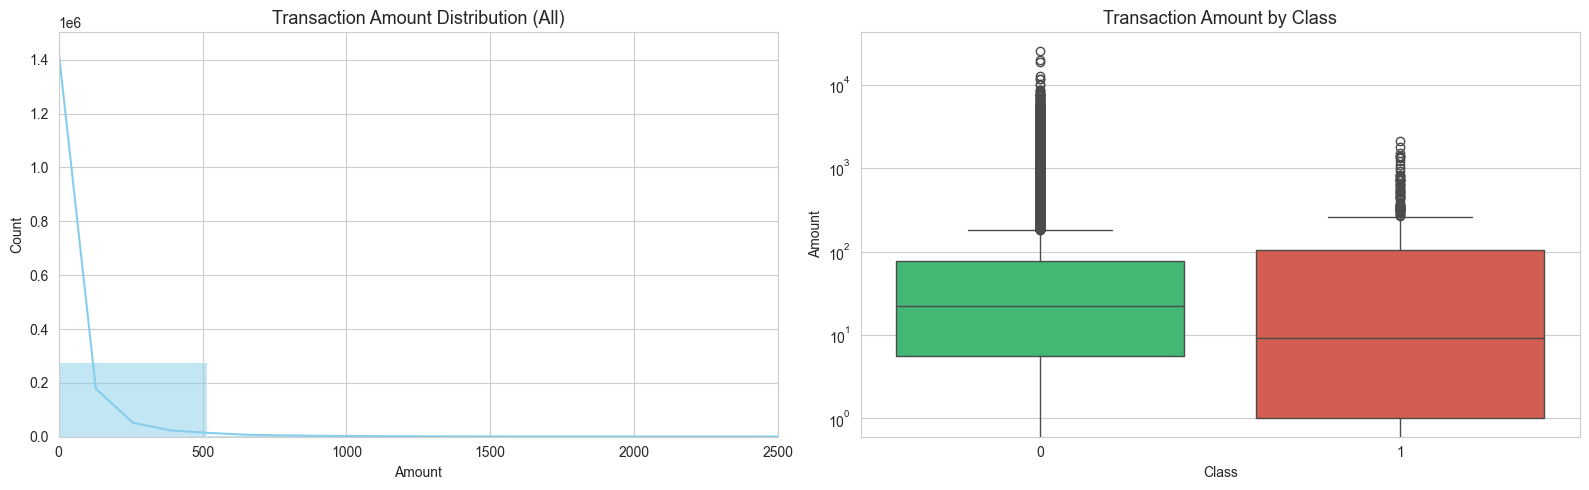


Amount statistics by Class:
            count     mean      std    min    25%     50%      75%        max
Class                                                                        
0     284315.0000  88.2910 250.1051 0.0000 5.6500 22.0000  77.0500 25691.1600
1        492.0000 122.2113 256.6833 0.0000 1.0000  9.2500 105.8900  2125.8700


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Amount distribution (all transactions)
sns.histplot(df['Amount'], bins=50, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Transaction Amount Distribution (All)', fontsize=13)
axes[0].set_xlabel('Amount')
axes[0].set_xlim([0, 2500])   # Most transactions are small

# Amount by Class
sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Transaction Amount by Class', fontsize=13)
axes[1].set_yscale('log')  # Log scale because of outliers

plt.tight_layout()
plt.show()

print("\nAmount statistics by Class:")
print(df.groupby('Class')['Amount'].describe())

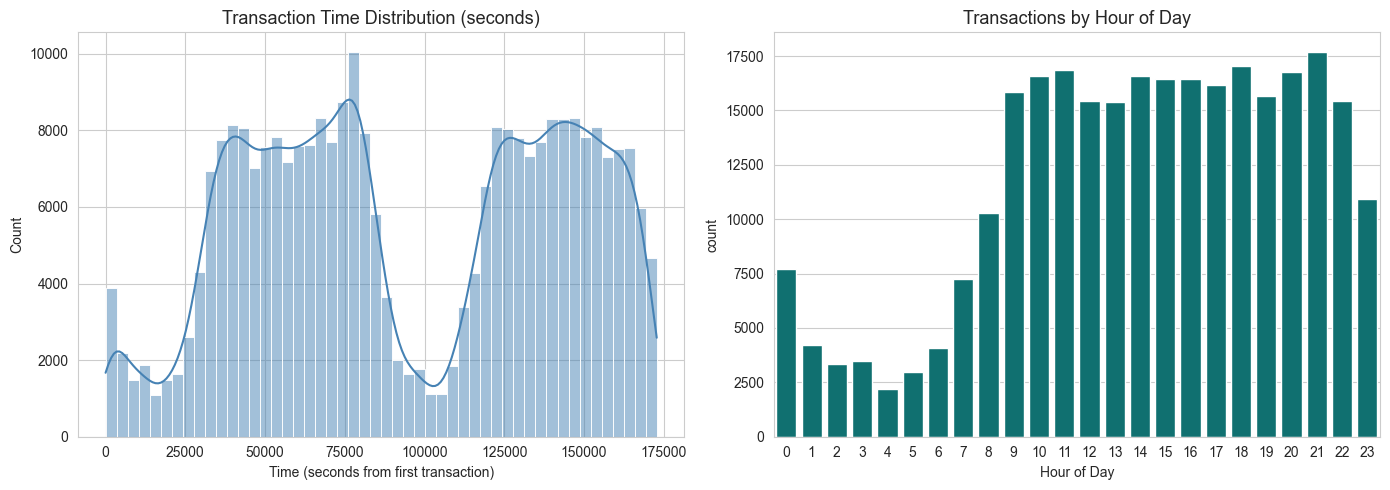

In [10]:
# Convert Time (seconds) to hours for better understanding
df['Hour'] = (df['Time'] // 3600) % 24

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Time'], bins=50, color='steelblue', kde=True)
plt.title('Transaction Time Distribution (seconds)', fontsize=13)
plt.xlabel('Time (seconds from first transaction)')

plt.subplot(1, 2, 2)
sns.countplot(x='Hour', data=df, color='teal')
plt.title('Transactions by Hour of Day', fontsize=13)
plt.xlabel('Hour of Day')

plt.tight_layout()
plt.show()

Correlation with Class (Fraud):
Class     1.0000
V11       0.1549
V4        0.1334
V2        0.0913
V21       0.0404
V19       0.0348
V20       0.0201
V8        0.0199
V27       0.0176
V28       0.0095
Amount    0.0056
V26       0.0045
V25       0.0033
V22       0.0008
V23      -0.0027
V15      -0.0042
V13      -0.0046
V24      -0.0072
Time     -0.0123
Hour     -0.0171
V6       -0.0436
V5       -0.0950
V9       -0.0977
V1       -0.1013
V18      -0.1115
V7       -0.1873
V3       -0.1930
V16      -0.1965
V10      -0.2169
V12      -0.2606
V14      -0.3025
V17      -0.3265
Name: Class, dtype: float64


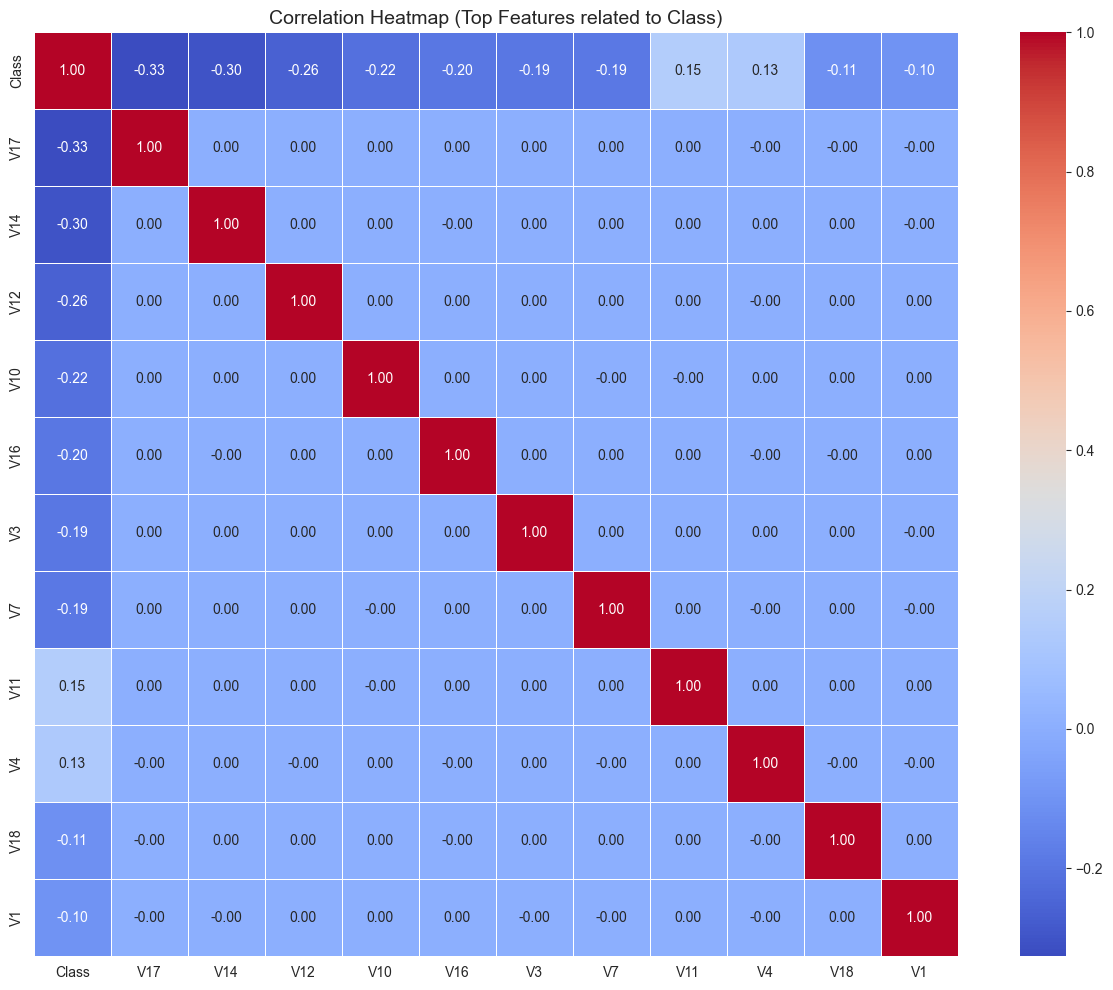

In [11]:
plt.figure(figsize=(16, 12))
corr = df.corr()

# Focus on correlation with the target
target_corr = corr['Class'].sort_values(ascending=False)
print("Correlation with Class (Fraud):")
print(target_corr)

# Heatmap of top correlated features
top_features = target_corr.abs().sort_values(ascending=False).head(12).index
sns.heatmap(df[top_features].corr(), annot=True, cmap='coolwarm', 
            fmt='.2f', linewidths=0.5, square=True)
plt.title('Correlation Heatmap (Top Features related to Class)', fontsize=14)
plt.show()

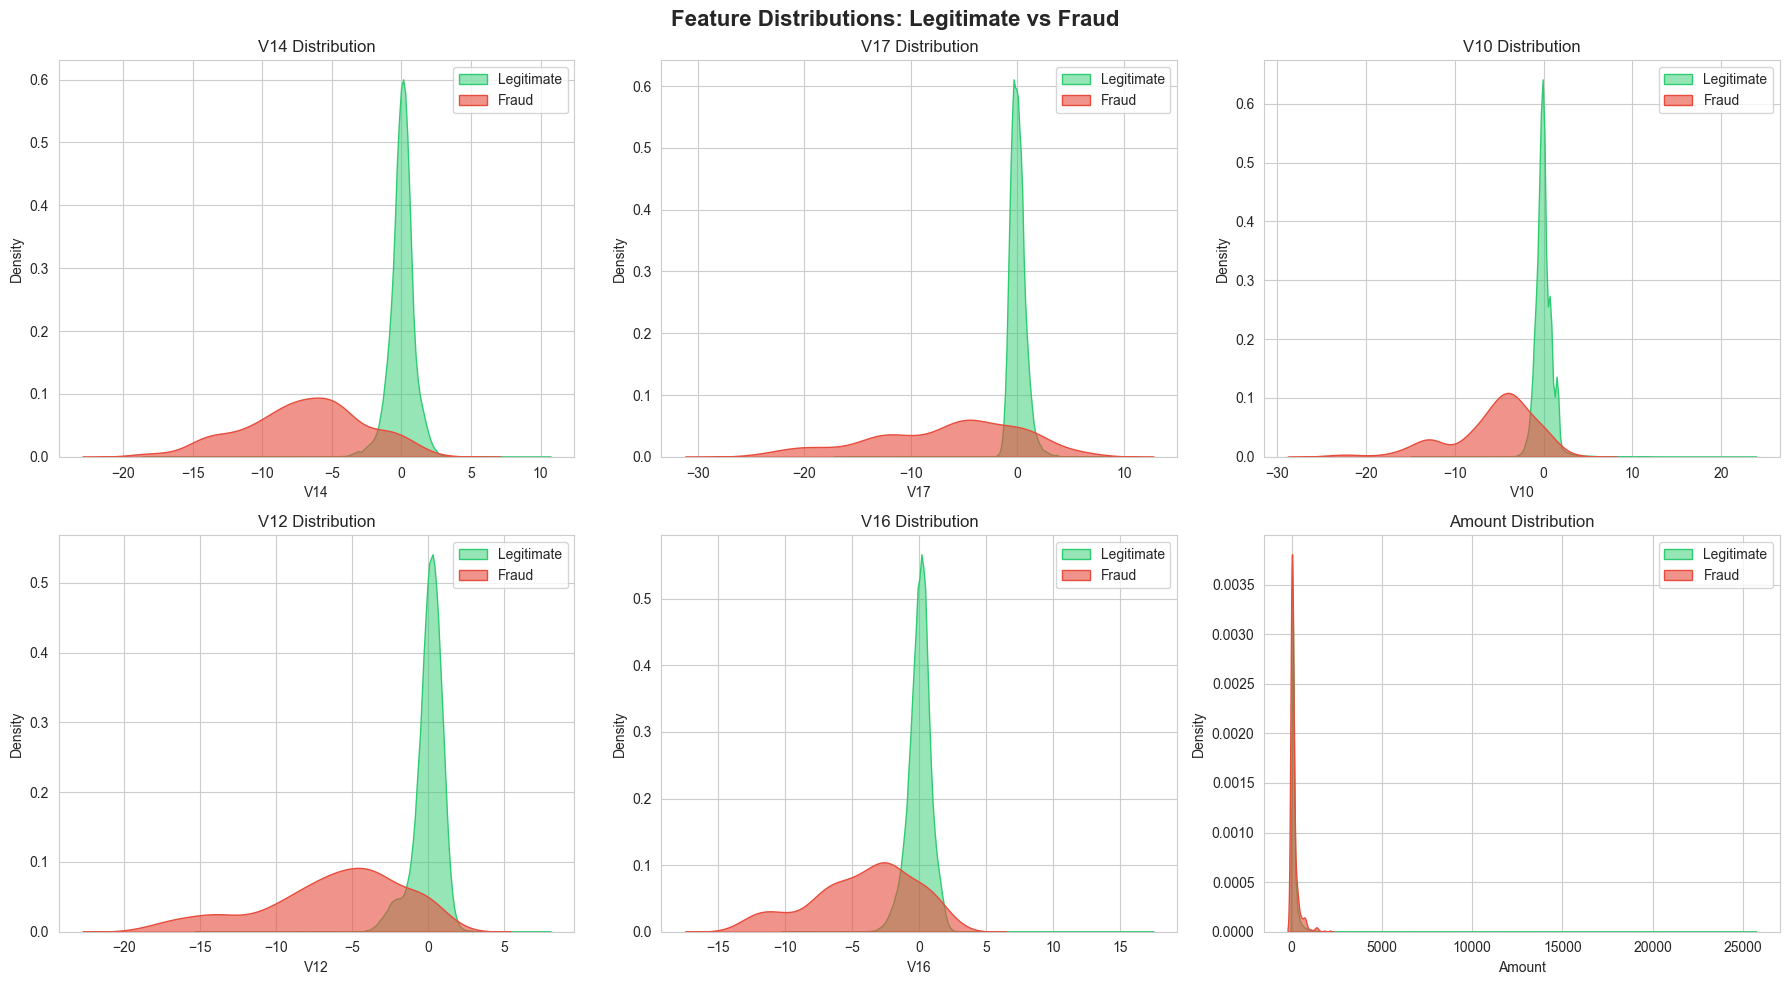

In [12]:
# Select a few important PCA features + Amount
important_features = ['V14', 'V17', 'V10', 'V12', 'V16', 'Amount']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(important_features):
    sns.kdeplot(data=df[df['Class']==0][feature], label='Legitimate', 
                ax=axes[i], fill=True, color='#2ecc71', alpha=0.5)
    sns.kdeplot(data=df[df['Class']==1][feature], label='Fraud', 
                ax=axes[i], fill=True, color='#e74c3c', alpha=0.6)
    axes[i].set_title(f'{feature} Distribution', fontsize=12)
    axes[i].legend()

plt.suptitle('Feature Distributions: Legitimate vs Fraud', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
# We will scale only 'Amount' and 'Time' (V1-V28 are already PCA scaled)

scaler = RobustScaler()   # RobustScaler is better when there are outliers (especially in Amount)

df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled'] = scaler.fit_transform(df[['Time']])

# Drop original Amount and Time (optional – keep if you want)
# We keep original for reference, but will use scaled versions for modeling

print("Scaling completed using RobustScaler")
df[['Time', 'Time_scaled', 'Amount', 'Amount_scaled']].head()

Scaling completed using RobustScaler


,Time,Time_scaled,Amount,Amount_scaled
0,0,-0.9950,149.6200,1.7833
1,0,-0.9950,2.6900,-0.2698
2,1,-0.9950,378.6600,4.9837
3,1,-0.9950,123.5000,1.4183
4,2,-0.9950,69.9900,0.6706


In [14]:
# Final feature set
feature_cols = [col for col in df.columns if col.startswith('V')] + ['Time_scaled', 'Amount_scaled']

X = df[feature_cols]
y = df['Class']

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape        : {y.shape}")

# Stratified train-test split (very important for imbalanced data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("\nTrain-Test Split completed (80-20 stratified)")
print(f"X_train: {X_train.shape} | y_train fraud rate: {y_train.mean()*100:.4f}%")
print(f"X_test : {X_test.shape}  | y_test  fraud rate: {y_test.mean()*100:.4f}%")

Feature matrix shape: (284807, 30)
Target shape        : (284807,)

Train-Test Split completed (80-20 stratified)
X_train: (227845, 30) | y_train fraud rate: 0.1729%
X_test : (56962, 30)  | y_test  fraud rate: 0.1720%


In [15]:
import os

# Create processed folder if it doesn't exist
os.makedirs('../data/processed', exist_ok=True)

# Save as parquet (much faster & smaller than csv)
X_train.to_parquet('../data/processed/X_train.parquet')
X_test.to_parquet('../data/processed/X_test.parquet')
y_train.to_frame(name='Class').to_parquet('../data/processed/y_train.parquet')
y_test.to_frame(name='Class').to_parquet('../data/processed/y_test.parquet')

print("Processed data saved successfully in '../data/processed/'")
print("Files created:")
print(" - X_train.parquet")
print(" - X_test.parquet")
print(" - y_train.parquet")
print(" - y_test.parquet")

Processed data saved successfully in '../data/processed/'
Files created:
 - X_train.parquet
 - X_test.parquet
 - y_train.parquet
 - y_test.parquet


## Summary of this Notebook

**Key Findings:**
- The dataset is extremely imbalanced (~0.17% fraud).
- Most transactions have very small amounts.
- Several PCA features (especially V14, V17, V10, V12) show clear separation between fraud and legitimate transactions.
- Time of day also shows some patterns.

**Preprocessing done:**
- Robust scaling applied on `Amount` and `Time`
- Stratified 80/20 train-test split
- Processed data saved for next notebooks

**Next Notebook:** `02_Imbalance_Handling_and_Modeling.ipynb`